In [40]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split

In [3]:
print(tf.__version__)

2.21.0


In [4]:
(x_train,y_train),(x_test,y_test)= imdb.load_data(num_words=10000)

In [6]:
x_test.shape

(25000,)

In [7]:
x_train[:][:]

array([list([1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]),
       list([1, 194, 1153, 194, 8255, 78, 228,

In [8]:
y_train[100]

np.int64(0)

In [13]:
word_index=imdb.get_word_index()

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 3s 2us/step


In [17]:
len(word_index)

88584

In [19]:
print("First 10 vocabulary entries:")

for word, index in list(word_index.items())[:10]:
    print(word, ":", index)

First 10 vocabulary entries:
fawn : 34701
tsukino : 52006
nunnery : 52007
sonja : 16816
vani : 63951
woods : 1408
spiders : 16115
hanging : 2345
woody : 2289
trawling : 52008


In [23]:
max_length = 200

x_train_pad = pad_sequences(
    x_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

x_test_pad = pad_sequences(
    x_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [24]:
print("Original review length:", len(x_train[0]))
print("Padded training shape:", x_train_pad.shape)
print("Padded testing shape:", x_test_pad.shape)
print("First padded review:", x_train_pad[0][:30])

Original review length: 218
Padded training shape: (25000, 200)
Padded testing shape: (25000, 200)
First padded review: [   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480]


In [36]:
vocab_size=10000
Embedding_dim=64
lstm_units=64

embedding_model=Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=Embedding_dim
    ),
    LSTM(lstm_units),
    Dense(1,activation="sigmoid")
])

In [27]:
sample_reviews=tf.convert_to_tensor(x_train_pad[:2])
sample_vectors=embedding_model(sample_reviews)

In [28]:
sample_vectors.shape

TensorShape([2, 200, 64])

In [37]:
embedding_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print("Trainable parameters: ",embedding_model.count_params())

Trainable parameters:  640000


In [35]:
LSTM(64)

<LSTM name=lstm, built=False>

In [39]:
embedding_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [44]:
x_train_final,x_val,y_train_final,y_val= train_test_split(
    x_train_pad,y_train,test_size=0.2,random_state=42,stratify=y_train
)

In [45]:
print("Training samples: ",len(x_train_final))
print("Validation samples: ",len(x_val))

Training samples:  20000
Validation samples:  5000


In [46]:
history=embedding_model.fit(
    x_train_final,y_train_final,epochs=5,batch_size=32,validation_data=(x_val,y_val),verbose=1
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 53ms/step - accuracy: 0.5333 - loss: 0.6872 - val_accuracy: 0.5952 - val_loss: 0.7234
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 31s 49ms/step - accuracy: 0.5998 - loss: 0.6528 - val_accuracy: 0.6228 - val_loss: 0.6553
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 51ms/step - accuracy: 0.7268 - loss: 0.5476 - val_accuracy: 0.7704 - val_loss: 0.5191
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 33s 53ms/step - accuracy: 0.8515 - loss: 0.3564 - val_accuracy: 0.8390 - val_loss: 0.3899
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 33s 52ms/step - accuracy: 0.9172 - loss: 0.2238 - val_accuracy: 0.8432 - val_loss: 0.3797


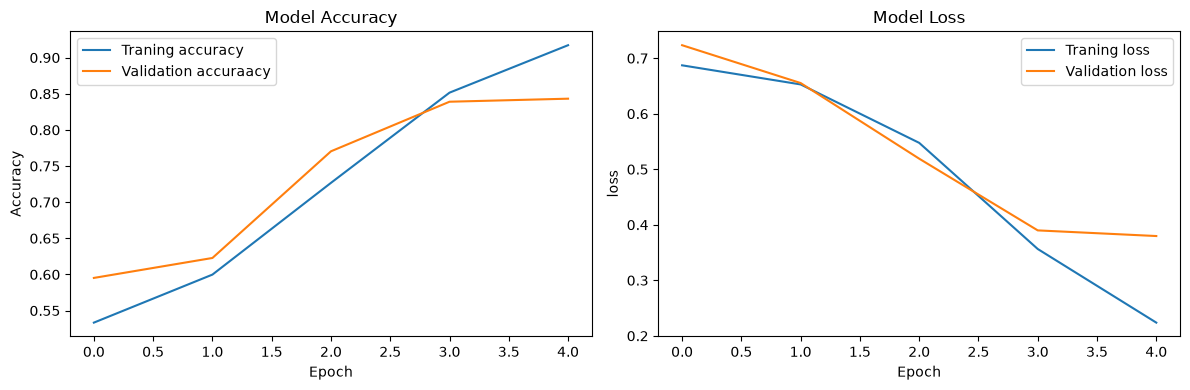

In [47]:
plt.figure(figsize=(12,4))

#accuracy plot
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"],label="Traning accuracy")
plt.plot(history.history["val_accuracy"],label="Validation accuraacy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


#loss plot
plt.subplot(1,2,2)
plt.plot(history.history["loss"],label="Traning loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.legend()

plt.tight_layout()
plt.show()

In [48]:
print("GPU devices: ",tf.config.list_physical_devices("GPU"))

GPU devices:  []
